# ÉTAPE 2 : PIPELINE DE PRÉTRAITEMENT AUDIO

In [ ]:
def preparer_audio(chemin_fichier, target_sr=16000):
    """
    Charge un fichier audio, le convertit en mono, le rééchantillonne à 16 kHz
    et normalise son amplitude.

    Paramètres :
    - chemin_fichier (str) : Chemin vers le fichier audio (.wav).
    - target_sr (int) : Taux d'échantillonnage cible (16000 Hz pour YAMNet).

    Retourne :
    - y_norm (np.ndarray) : Signal audio normalisé.
    - sr (int) : Taux d'échantillonnage final.
    """
    # 1. Chargement et conversion automatique en mono (mono=True)
    # librosa.load convertit par défaut les formats audio en float32 normalisés entre -1 et 1
    y, sr = librosa.load(chemin_fichier, sr=None, mono=True)

    # 2. Rééchantillonnage si le taux d'origine est différent de 16000 Hz
    if sr != target_sr:
        y = librosa.resample(y, orig_sr=sr, target_sr=target_sr)
        sr = target_sr

    # 3. Normalisation de l'amplitude (Peak Normalization)
    # On évite la division par zéro si le signal est totalement muet
    max_val = np.max(np.abs(y))
    if max_val > 0:
        y_norm = y / max_val
    else:
        y_norm = y

    return y_norm, sr

print("Fonction de prétraitement définie avec succès.")

Fonction de prétraitement définie avec succès.


VISUALISATION ET EXPLORATION DU DATASET ESC-50



Fichier CSV trouvé à l'emplacement : /content/drive/MyDrive/ESC-50/ESC-50-master/meta/esc50.csv
Dossier Audio trouvé à l'emplacement : /content/drive/MyDrive/ESC-50/ESC-50-master/audio

=== INFORMATIONS GÉNÉRALES SUR LE DATASET ===
Nombre total d'enregistrements : 2000
Nombre total de classes uniques : 50

Colonnes disponibles dans le fichier de métadonnées :
['filename', 'fold', 'target', 'category', 'esc10', 'src_file', 'take']

=== APERÇU DES 5 PREMIÈRES LIGNES ===


,filename,fold,target,category,esc10,src_file,take
0,1-100032-A-0.wav,1,0,dog,True,100032,A
1,1-100038-A-14.wav,1,14,chirping_birds,False,100038,A
2,1-100210-A-36.wav,1,36,vacuum_cleaner,False,100210,A
3,1-100210-B-36.wav,1,36,vacuum_cleaner,False,100210,B
4,1-101296-A-19.wav,1,19,thunderstorm,False,101296,A



Graphique de distribution sauvegardé dans : /content/drive/MyDrive/ESC-50/ESC-50-master/distribution_classes_esc50.png


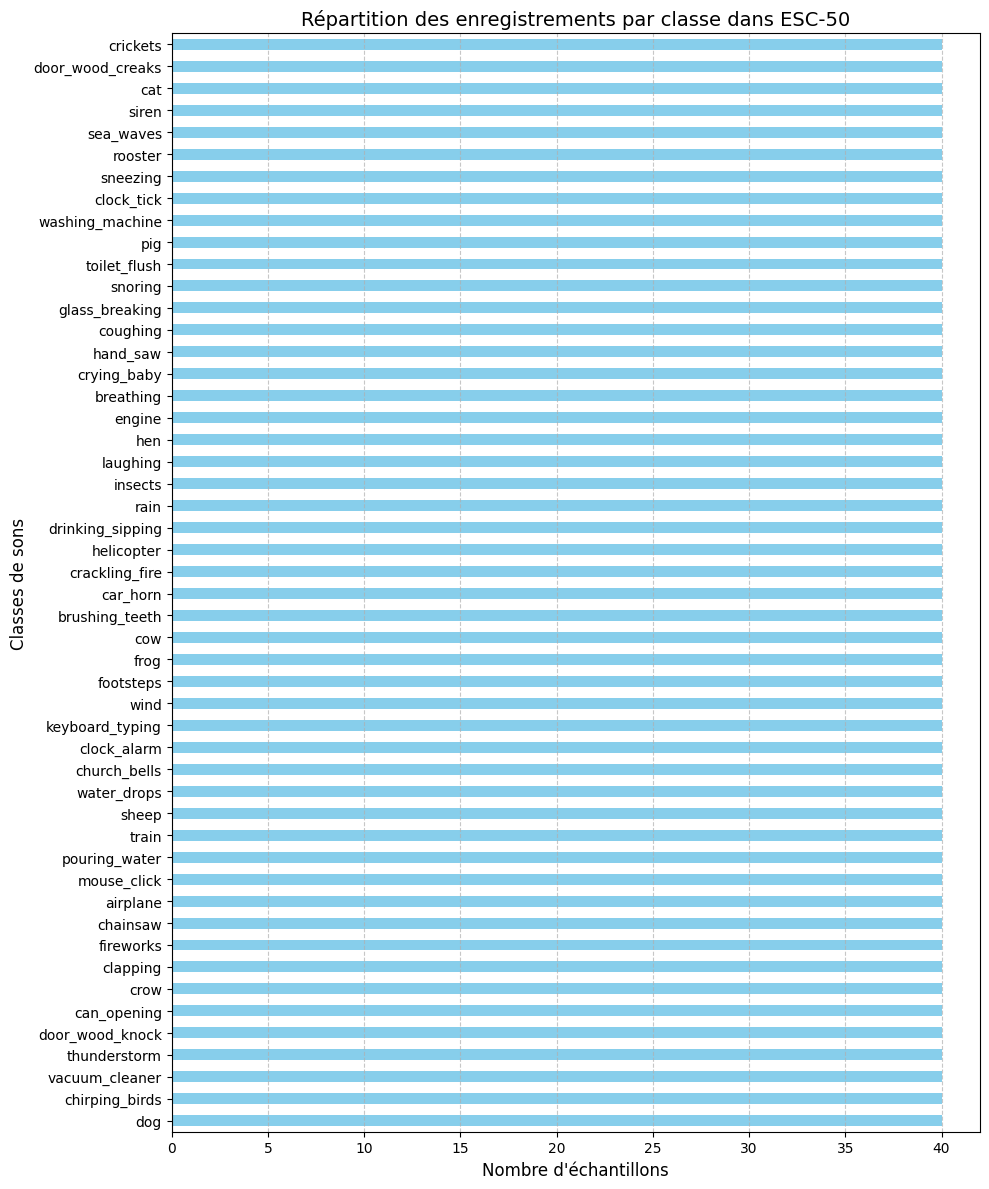

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import glob

# 1. Chemins vers les fichiers dans votre Google Drive
dossier_esc50 = '/content/drive/MyDrive/ESC-50'

# Recherche automatique du fichier CSV et du dossier audio s'ils sont dans un sous-dossier (ex: ESC-50-master)
chemins_csv = glob.glob(os.path.join(dossier_esc50, '**', 'esc50.csv'), recursive=True)

if not chemins_csv:
    raise FileNotFoundError("Impossible de trouver le fichier esc50.csv dans votre dossier Drive ESC-50. Vérifiez que la décompression s'est bien déroulée.")

csv_metadonnees = chemins_csv[0]
dossier_parent_dataset = os.path.dirname(os.path.dirname(csv_metadonnees))
dossier_audio = os.path.join(dossier_parent_dataset, 'audio')

print(f"Fichier CSV trouvé à l'emplacement : {csv_metadonnees}")
print(f"Dossier Audio trouvé à l'emplacement : {dossier_audio}")

# 2. Chargement du fichier CSV de métadonnées
df_meta = pd.read_csv(csv_metadonnees)

# 3. Affichage des informations de base
print("\n=== INFORMATIONS GÉNÉRALES SUR LE DATASET ===")
print(f"Nombre total d'enregistrements : {len(df_meta)}")
print(f"Nombre total de classes uniques : {df_meta['category'].nunique()}")
print("\nColonnes disponibles dans le fichier de métadonnées :")
print(df_meta.columns.tolist())

print("\n=== APERÇU DES 5 PREMIÈRES LIGNES ===")
display(df_meta.head())

# 4. Visualisation graphique de la répartition par classe (très utile pour le jury)
plt.figure(figsize=(10, 12))
df_meta['category'].value_counts().sort_values().plot(kind='barh', color='skyblue')
plt.title("Répartition des enregistrements par classe dans ESC-50", fontsize=14)
plt.xlabel("Nombre d'échantillons", fontsize=12)
plt.ylabel("Classes de sons", fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()

# Sauvegarde de la figure dans le Drive
chemin_graphique = os.path.join(dossier_parent_dataset, 'distribution_classes_esc50.png')
plt.savefig(chemin_graphique, dpi=300)
print(f"\nGraphique de distribution sauvegardé dans : {chemin_graphique}")

plt.show()

Extraction des classes visées et gestions de bruits d'environnement

In [ ]:
import os
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical
import json

# 1. Définition des chemins avec le sous-dossier ESC-50-master
dossier_esc50 = '/content/drive/MyDrive/ESC-50'
dossier_audio = os.path.join(dossier_esc50, 'ESC-50-master', 'audio')
csv_metadonnees = os.path.join(dossier_esc50, 'ESC-50-master', 'meta', 'esc50.csv')

# 2. Chargement du fichier CSV officiel
df_meta = pd.read_csv(csv_metadonnees)

# 3. FILTRAGE STRICT POUR NE GARDER QUE LES BRUITS DOMESTIQUES ET QUOTIDIENS
classes_domestiques_cibles = [
    'crying_baby',           # Bébé qui pleure
    'siren',              # Sirène
    'clapping',           # Applaudissements
    'door_wood_knock',    # Toc-toc à la porte
    'glass_breaking',     # Verre brisé
    'car_horn',           # Klaxon de voiture
    'pouring_water',      # Gouttes d'eau / fuite
    'washing_machine',    # Machine à laver
    'crackling_fire',      # Crépitement de feu
    'clock_alarm'         # Alarme de réveil
]

# Filtrage du DataFrame
df_filtre = df_meta[df_meta['category'].isin(classes_domestiques_cibles)].copy()

# Création d'un dictionnaire de mapping fixe (ex: 'baby_cry' -> 0, 'clock_alarm' -> 1, etc.)
classes_uniques = sorted(df_filtre['category'].unique())  # Trié pour garder un ordre strict au redémarrage
mapping_classes = {classe: idx for idx, classe in enumerate(classes_uniques)}
df_filtre['target_label'] = df_filtre['category'].map(mapping_classes)

print(f"Nombre total de fichiers de bruits domestiques sélectionnés : {len(df_filtre)}")
print(f"Classes incluses ({len(classes_uniques)} classes) :")
for nom, idx in mapping_classes.items():
    print(f" - ID {idx} : {nom}")

# Sauvegarder impérativement le mapping dans Google Drive !
chemin_mapping_drive = "/content/drive/MyDrive/mapping_classes.json"
with open(chemin_mapping_drive, "w") as f:
    json.dump(mapping_classes, f)

print("Mapping sauvegardé avec succès dans le Drive :", chemin_mapping_drive)

# 4. BOUCLE D'EXTRACTION DES EMBEDDINGS YAMNET AVEC SÉCURITÉ
X_embeddings = []
y_labels = []

print("\nDébut de l'extraction des embeddings YAMNet...")
for index, row in df_filtre.iterrows():
    nom_fichier = row['filename']
    label_id = row['target_label']

    chemin_complet = os.path.join(dossier_audio, nom_fichier)

    if os.path.exists(chemin_complet):
        try:
            # Utilisation sécurisée de la fonction d'extraction
            emb, _ = extraire_embeddings(chemin_complet, is_bytes=False)
            X_embeddings.append(emb)
            y_labels.append(label_id)
        except Exception as e:
            # Si un fichier WAV spécifique est corrompu ou illisible, on passe au suivant
            print(f"⚠️ Fichier ignoré car corrompu ou illisible : {nom_fichier} | Erreur : {e}")
    else:
        print(f"Alerte : Fichier introuvable -> {chemin_complet}")

# Conversion en tableaux NumPy
X_data = np.array(X_embeddings)
y_data = np.array(y_labels)

# Encodage en One-Hot pour correspondre à la fonction de perte 'binary_crossentropy'
y_data_onehot = to_categorical(y_data, num_classes=len(classes_uniques))

print(f"\nForme finale de la matrice X_data (Embeddings) : {X_data.shape}")
print(f"Forme finale de la matrice y_data_onehot (One-Hot) : {y_data_onehot.shape}")

Nombre total de fichiers de bruits domestiques sélectionnés : 400
Classes incluses (10 classes) :
 - ID 0 : car_horn
 - ID 1 : clapping
 - ID 2 : clock_alarm
 - ID 3 : crackling_fire
 - ID 4 : crying_baby
 - ID 5 : door_wood_knock
 - ID 6 : glass_breaking
 - ID 7 : pouring_water
 - ID 8 : siren
 - ID 9 : washing_machine
Mapping sauvegardé avec succès dans le Drive : /content/drive/MyDrive/mapping_classes.json

Début de l'extraction des embeddings YAMNet...


/tmp/ipykernel_2631/2260703495.py:24: UserWarning: PySoundFile failed. Trying audioread instead.
  y, sr = librosa.load(source_audio, sr=None, mono=True)
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


⚠️ Fichier ignoré car corrompu ou illisible : 2-89516-A-37.wav | Erreur : 

Forme finale de la matrice X_data (Embeddings) : (399, 1024)
Forme finale de la matrice y_data_onehot (One-Hot) : (399, 10)
